# UNIT 3 — PCA + Clustering
## Find groups of similar network traffic

In [ ]:
import pandas as pd                      # for working with tables
import numpy as np                       # for numbers
import matplotlib.pyplot as plt          # for charts

from sklearn.preprocessing import StandardScaler   # puts every column on the same scale
from sklearn.decomposition import PCA              # squashes many columns into a few
from sklearn.cluster import KMeans                 # finds groups of similar rows
from sklearn.metrics import silhouette_score       # scores how well separated the groups are

print("Ready.")

Ready.


In [ ]:
column_names = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty",
]

# If the download ever fails: download KDDTrain+.txt and KDDTest+.txt from
# https://www.unb.ca/cic/datasets/nsl.html , upload them with the folder icon on the left,
# and write their names here, like {"train": "KDDTrain+.txt", "test": "KDDTest+.txt"}
LOCAL_FILES = {"train": None, "test": None}

base = "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/"
web_links = {
    "train": [base + "KDDTrain%2B.txt", base + "KDDTrain+.txt"],
    "test":  [base + "KDDTest%2B.txt",  base + "KDDTest+.txt"],
}

def load_nsl(which):
    places = ([LOCAL_FILES[which]] if LOCAL_FILES[which] else []) + web_links[which]
    for place in places:
        try:
            df = pd.read_csv(place, header=None, names=column_names)
            if len(df) > 1000 and df.shape[1] == 43:
                print(f"{which:<5}: {len(df):,} rows loaded")
                return df
        except Exception:
            pass          # that place did not work, try the next one
    raise RuntimeError("Could not load the " + which + " file. See the note above this cell.")

train = load_nsl("train")
test  = load_nsl("test")
train.head(3)

train: 125,973 rows loaded
test : 22,544 rows loaded


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.0,0.0,0.0,0.05,0.0,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.0,0.0,0.0,0.00,0.0,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.0,1.0,1.0,0.00,0.0,neptune,19


In [ ]:
dos_attacks   = ["neptune", "smurf", "back", "teardrop", "pod", "land",
                 "apache2", "mailbomb", "processtable", "udpstorm", "worm"]
probe_attacks = ["satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"]
r2l_attacks   = ["guess_passwd", "ftp_write", "imap", "phf", "multihop", "warezmaster",
                 "warezclient", "spy", "xlock", "xsnoop", "snmpguess", "snmpgetattack",
                 "httptunnel", "sendmail", "named"]
u2r_attacks   = ["buffer_overflow", "loadmodule", "rootkit", "perl", "sqlattack", "xterm", "ps"]

def family_of(label):
    if label == "normal":          return "normal"
    if label in dos_attacks:       return "dos"
    if label in probe_attacks:     return "probe"
    if label in r2l_attacks:       return "r2l"
    if label in u2r_attacks:       return "u2r"
    return "other"

for df in (train, test):
    df["label"]  = df["label"].str.strip()
    df["family"] = df["label"].apply(family_of)
    df["attack"] = (df["label"] != "normal").astype(int)     # 1 = attack, 0 = normal

counts = pd.DataFrame({"KDDTrain+": train["family"].value_counts(),
                       "KDDTest+":  test["family"].value_counts()}).fillna(0).astype(int)
counts.sort_values("KDDTrain+", ascending=False)

,KDDTrain+,KDDTest+
family,,
normal,67343,9711
dos,45927,7460
probe,11656,2421
r2l,995,2885
u2r,52,67


In [ ]:
not_features = ["protocol_type", "service", "flag", "label", "difficulty", "family", "attack"]
feature_columns = [c for c in train.columns if c not in not_features]

# columns that never change are useless
never_changes = [c for c in feature_columns if train[c].std() == 0]
feature_columns = [c for c in feature_columns if c not in never_changes]

print("Columns used by PCA:", len(feature_columns))
print("Dropped because they never change:", never_changes)
print()
print(feature_columns)

Columns used by PCA: 37
Dropped because they never change: ['num_outbound_cmds']

['duration', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']


In [ ]:
log_columns = [c for c in feature_columns if train[c].max() > 1000]

def prepare(df):
    """Take a table of connections, return only the chosen columns, with giant ones logged."""
    X = df[feature_columns].astype(float).copy()
    for c in log_columns:
        X[c] = np.log1p(X[c])
    return X

X_train = prepare(train)
X_test  = prepare(test)

print("Columns we applied the log to:", log_columns)
print()
print("Largest src_bytes before the log:", int(train["src_bytes"].max()))
print("Largest src_bytes after the log :", round(X_train["src_bytes"].max(), 2))

Columns we applied the log to: ['duration', 'src_bytes', 'dst_bytes', 'num_compromised', 'num_root']

Largest src_bytes before the log: 1379963888
Largest src_bytes after the log : 21.05


In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)    # learn from the training file
X_test_scaled  = scaler.transform(X_test)         # reuse those numbers for the test file

print("Training table shape:", X_train_scaled.shape, "  (rows, columns)")
print("Test table shape    :", X_test_scaled.shape)
print()
print("Average of the first 5 columns after scaling:", np.round(X_train_scaled.mean(axis=0)[:5], 2))
print("Spread of the first 5 columns after scaling :", np.round(X_train_scaled.std(axis=0)[:5], 2))

Training table shape: (125973, 37)   (rows, columns)
Test table shape    : (22544, 37)

Average of the first 5 columns after scaling: [-0.  0. -0. -0.  0.]
Spread of the first 5 columns after scaling : [1. 1. 1. 1. 1.]


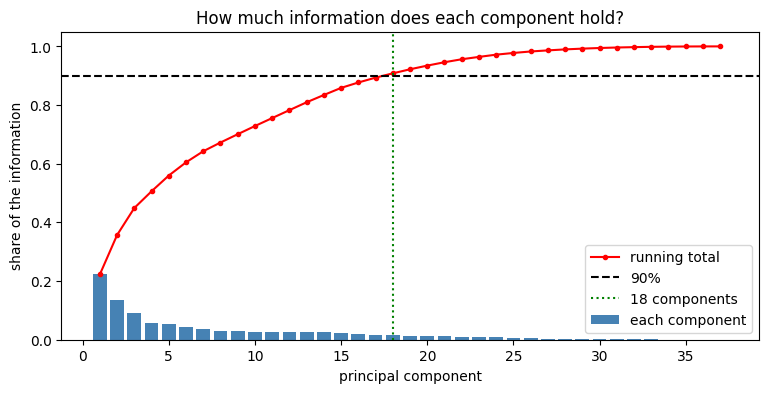

Original columns                          : 37
Components needed to keep 90% of the info : 18
Component 1 alone holds                   : 22.3 %


In [ ]:
pca_full = PCA(random_state=42).fit(X_train_scaled)     # keep ALL components, just to look

share = pca_full.explained_variance_ratio_              # information held by each component
running_total = np.cumsum(share)

components_for_90 = int(np.argmax(running_total >= 0.90) + 1)

plt.figure(figsize=(9, 4))
positions = np.arange(1, len(share) + 1)
plt.bar(positions, share, color="steelblue", label="each component")
plt.plot(positions, running_total, color="red", marker="o", markersize=3, label="running total")
plt.axhline(0.90, color="black", linestyle="--", label="90%")
plt.axvline(components_for_90, color="green", linestyle=":", label=f"{components_for_90} components")
plt.xlabel("principal component")
plt.ylabel("share of the information")
plt.title("How much information does each component hold?")
plt.legend()
plt.show()

print("Original columns                          :", len(share))
print("Components needed to keep 90% of the info :", components_for_90)
print("Component 1 alone holds                   :", round(share[0] * 100, 1), "%")

In [ ]:
for i in range(3):
    weights = pd.Series(pca_full.components_[i], index=feature_columns)
    top5 = weights.reindex(weights.abs().sort_values(ascending=False).index)[:5].round(2)
    print(f"Component {i + 1} holds {share[i] * 100:.1f}% and is mostly:")
    print(top5.to_string())
    print()

Component 1 holds 22.3% and is mostly:
same_srv_rate               0.32
dst_host_same_srv_rate      0.30
src_bytes                   0.30
dst_host_srv_serror_rate   -0.29
dst_host_serror_rate       -0.29

Component 2 holds 13.4% and is mostly:
srv_rerror_rate             0.41
rerror_rate                 0.41
dst_host_srv_rerror_rate    0.41
dst_host_rerror_rate        0.40
dst_host_diff_srv_rate      0.23

Component 3 holds 9.2% and is mostly:
su_attempted        0.49
num_compromised     0.47
num_root            0.45
root_shell          0.39
num_access_files    0.37



In [ ]:
pca = PCA(n_components=components_for_90, random_state=42)
Z_train = pca.fit_transform(X_train_scaled)
Z_test  = pca.transform(X_test_scaled)

info_kept = pca.explained_variance_ratio_.sum() * 100

print("Training table before PCA:", X_train_scaled.shape)
print("Training table after PCA :", Z_train.shape)
print("Information kept         :", round(info_kept, 1), "%")

Training table before PCA: (125973, 37)
Training table after PCA : (125973, 18)
Information kept         : 90.8 %


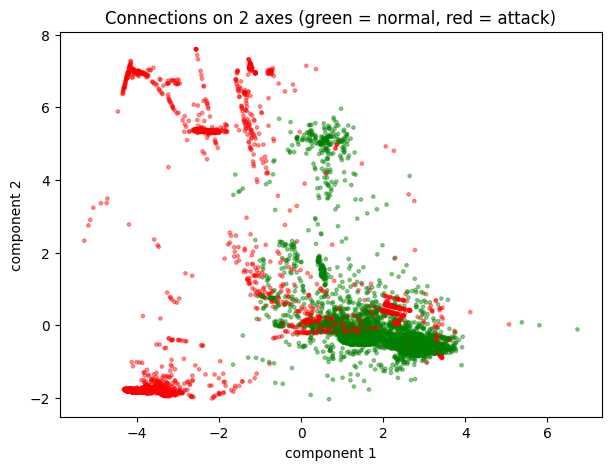

In [ ]:
rng = np.random.default_rng(42)
pick = rng.choice(len(Z_train), size=10000, replace=False)
colours = train["attack"].to_numpy()[pick]

plt.figure(figsize=(7, 5))
plt.scatter(Z_train[pick, 0], Z_train[pick, 1],
            c=np.where(colours == 1, "red", "green"), s=6, alpha=0.4)
plt.xlabel("component 1")
plt.ylabel("component 2")
plt.title("Connections on 2 axes (green = normal, red = attack)")
plt.show()

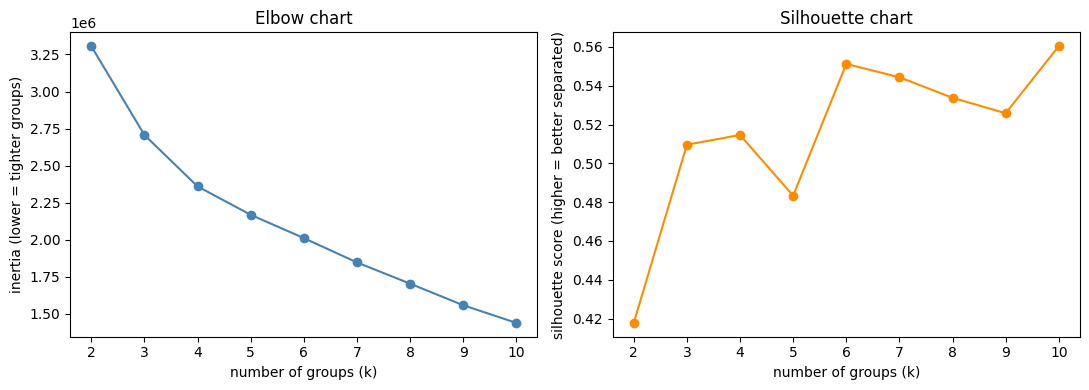

 k  silhouette
 2       0.418
 3       0.510
 4       0.515
 5       0.483
 6       0.551
 7       0.544
 8       0.534
 9       0.526
10       0.560

Number of groups we will use: 10


In [ ]:
k_values = list(range(2, 11))
inertias, silhouettes = [], []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=5, random_state=42).fit(Z_train)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(Z_train, km.labels_, sample_size=10000, random_state=42))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(k_values, inertias, marker="o", color="steelblue")
axes[0].set_xlabel("number of groups (k)")
axes[0].set_ylabel("inertia (lower = tighter groups)")
axes[0].set_title("Elbow chart")

axes[1].plot(k_values, silhouettes, marker="o", color="darkorange")
axes[1].set_xlabel("number of groups (k)")
axes[1].set_ylabel("silhouette score (higher = better separated)")
axes[1].set_title("Silhouette chart")

plt.tight_layout()
plt.show()

print(pd.DataFrame({"k": k_values, "silhouette": np.round(silhouettes, 3)}).to_string(index=False))

# --- pick k ---------------------------------------------------------------
CHOSEN_K = None        # type a number here (like 6) to override the automatic choice
MIN_K = 4              # automatic choice only looks at k = 4 or more

if CHOSEN_K is None:
    allowed = [(s, k) for k, s in zip(k_values, silhouettes) if k >= MIN_K]
    best_k = max(allowed)[1]
else:
    best_k = CHOSEN_K

print()
print("Number of groups we will use:", best_k)

In [ ]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
train["cluster"] = kmeans.fit_predict(Z_train)

sizes = train["cluster"].value_counts().sort_index()
print("Connections in each cluster:")
print(sizes.to_string())

Connections in each cluster:
cluster
0    57365
1    34872
2    14137
3     4995
4       25
5     1190
6     3096
7       74
8      884
9     9335


In [ ]:
key_features = ["duration", "src_bytes", "dst_bytes", "count", "srv_count",
                "serror_rate", "rerror_rate", "same_srv_rate", "diff_srv_rate", "logged_in"]

profile = train.groupby("cluster")[key_features].mean().round(2)
profile.insert(0, "size", sizes)
profile

,size,duration,src_bytes,dst_bytes,count,srv_count,serror_rate,rerror_rate,same_srv_rate,diff_srv_rate,logged_in
cluster,,,,,,,,,,,
0,57365,2.31,25780.75,5462.91,7.92,9.98,0.01,0.00,0.96,0.03,0.83
1,34872,0.00,2.21,3.38,168.77,10.95,1.00,0.00,0.12,0.08,0.00
2,14137,0.23,14.11,5.60,148.51,6.02,0.01,0.96,0.35,0.22,0.00
3,4995,1.90,1098.84,659.39,1.06,19.25,0.01,0.01,1.00,0.01,0.07
4,25,0.00,0.00,0.00,4.16,1.80,0.97,0.03,0.93,0.04,0.00
5,1190,345.48,942.43,2656.12,1.07,1.02,0.01,0.00,0.98,0.04,1.00
6,3096,11276.80,1373243.55,696128.20,2.11,1.52,0.00,0.39,0.90,0.09,0.12
7,74,9504.12,1164.39,213366.05,1.03,1.01,0.14,0.03,0.99,0.01,1.00
8,884,0.00,28.00,0.06,61.52,50.83,0.07,0.00,0.92,0.01,0.00


In [ ]:
table = pd.crosstab(train["cluster"], train["family"])

cluster_name = table.idxmax(axis=1)                      # each cluster is named after its biggest family
purity = (table.max(axis=1) / table.sum(axis=1) * 100).round(1)

check = table.copy()
check["biggest family"] = cluster_name
check["purity %"] = purity
check

family,dos,normal,probe,r2l,u2r,biggest family,purity %
cluster,,,,,,,
0,1233,54288,1369,446,29,normal,94.6
1,34323,73,472,4,0,dos,98.4
2,6892,2713,4484,48,0,dos,48.8
3,113,684,4076,117,5,probe,81.6
4,18,7,0,0,0,dos,72.0
5,0,877,0,313,0,normal,73.7
6,0,1930,1082,66,18,normal,62.3
7,0,73,0,1,0,normal,98.6
8,884,0,0,0,0,dos,100.0


In [ ]:
train["cluster_name"] = train["cluster"].map(cluster_name)

overall_purity = table.max(axis=1).sum() / len(train) * 100
baseline       = train["family"].value_counts().max() / len(train) * 100
normal_vs_attack = ((train["cluster_name"] == "normal") == (train["family"] == "normal")).mean() * 100

print(f"Overall purity (all families)              : {overall_purity:.1f}%")
print(f"Baseline (just guess the biggest family)   : {baseline:.1f}%")
print(f"Normal-vs-attack agreement                 : {normal_vs_attack:.1f}%")
print()

# for each family: what share of its connections sit in a cluster named after it?
found = ((train["cluster_name"] == train["family"]).groupby(train["family"]).mean() * 100).round(1)
print("Share of each family that landed in a cluster named after it:")
print(found.to_string())

Overall purity (all families)              : 87.4%
Baseline (just guess the biggest family)   : 53.5%
Normal-vs-attack agreement                 : 91.5%

Share of each family that landed in a cluster named after it:
family
dos       91.7
normal    94.8
probe     35.0
r2l        0.0
u2r        0.0


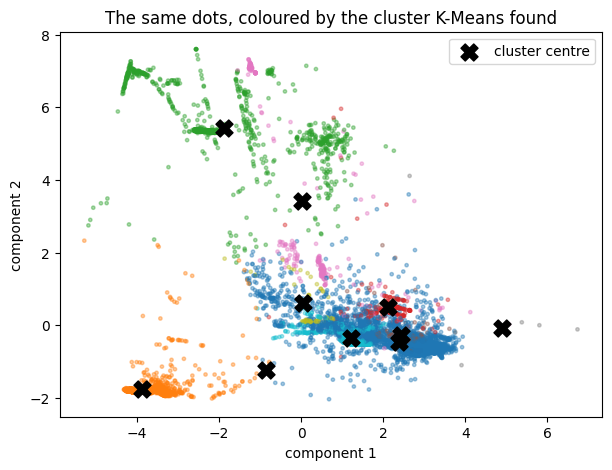

In [ ]:
centres = kmeans.cluster_centers_

plt.figure(figsize=(7, 5))
plt.scatter(Z_train[pick, 0], Z_train[pick, 1],
            c=train["cluster"].to_numpy()[pick], cmap="tab10", s=6, alpha=0.4)
plt.scatter(centres[:, 0], centres[:, 1], c="black", marker="X", s=150, label="cluster centre")
plt.xlabel("component 1")
plt.ylabel("component 2")
plt.title("The same dots, coloured by the cluster K-Means found")
plt.legend()
plt.show()

In [ ]:
# distance to the nearest cluster centre, for every connection
distance_train = kmeans.transform(Z_train).min(axis=1)
distance_test  = kmeans.transform(Z_test).min(axis=1)

threshold = np.percentile(distance_train, 95)

test["cluster"]   = kmeans.predict(Z_test)
test["distance"]  = distance_test
test["looks_new"] = test["distance"] > threshold

# sort every test connection into one of three groups
attack_names_in_train = set(train["label"])

def group_of(label):
    if label == "normal":                  return "normal traffic"
    if label in attack_names_in_train:     return "attack type seen in KDDTrain+"
    return "attack type NEVER seen in KDDTrain+"

test["group"] = test["label"].apply(group_of)
unseen_names = sorted(set(test["label"]) - attack_names_in_train - {"normal"})

print("Distance limit (95th percentile of the training traffic):", round(threshold, 3))
print("Attack types in KDDTest+ that never appear in KDDTrain+ :", len(unseen_names))
print(unseen_names)
print()

flag_by_group = test.groupby("group")["looks_new"].agg(["size", "mean"])
flag_by_group["mean"] = (flag_by_group["mean"] * 100).round(1)
flag_by_group.columns = ["connections", "% flagged as unusual"]
flag_by_group

Distance limit (95th percentile of the training traffic): 4.801
Attack types in KDDTest+ that never appear in KDDTrain+ : 17
['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']



,connections,% flagged as unusual
group,,
attack type NEVER seen in KDDTrain+,3750,29.0
attack type seen in KDDTrain+,9083,21.6
normal traffic,9711,3.0


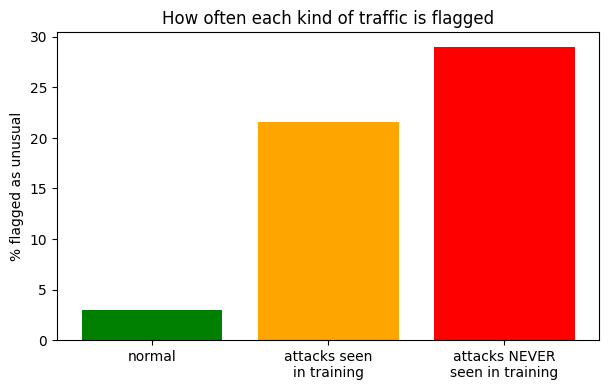

In [ ]:
plt.figure(figsize=(7, 4))
order = ["normal traffic", "attack type seen in KDDTrain+", "attack type NEVER seen in KDDTrain+"]
rates = [flag_by_group.loc[g, "% flagged as unusual"] if g in flag_by_group.index else 0 for g in order]
plt.bar(["normal", "attacks seen\nin training", "attacks NEVER\nseen in training"], rates,
        color=["green", "orange", "red"])
plt.ylabel("% flagged as unusual")
plt.title("How often each kind of traffic is flagged")
plt.show()

In [ ]:
unseen_table = (test[test["group"] == "attack type NEVER seen in KDDTrain+"]
                .groupby("label")["looks_new"].agg(["size", "mean"])
                .sort_values("size", ascending=False))
unseen_table["mean"] = (unseen_table["mean"] * 100).round(1)
unseen_table.columns = ["connections", "% flagged as unusual"]

print("Flag rate by family on KDDTest+:")
print((test.groupby("family")["looks_new"].mean() * 100).round(1).to_string())
print()
unseen_table.head(10)

Flag rate by family on KDDTest+:
family
dos        5.8
normal     3.0
probe     58.9
r2l       39.9
u2r       62.7



,connections,% flagged as unusual
label,,
mscan,996,44.2
apache2,737,53.2
processtable,685,2.9
snmpguess,331,0.0
saint,319,61.8
mailbomb,293,0.0
snmpgetattack,178,0.0
httptunnel,133,1.5
named,17,23.5


In [ ]:
test["cluster_name"] = test["cluster"].map(cluster_name)

test_purity_style = (test["cluster_name"] == test["family"]).mean() * 100
test_normal_vs_attack = ((test["cluster_name"] == "normal") == (test["family"] == "normal")).mean() * 100

compare = pd.DataFrame({
    "family match %":            [round(overall_purity, 1), round(test_purity_style, 1)],
    "normal-vs-attack match %":  [round(normal_vs_attack, 1), round(test_normal_vs_attack, 1)],
}, index=["KDDTrain+ (seen)", "KDDTest+ (unseen)"])
compare

,family match %,normal-vs-attack match %
KDDTrain+ (seen),87.4,91.5
KDDTest+ (unseen),65.6,76.3


In [ ]:
def check_row(row_number):
    row = test.loc[row_number]
    print("Real label        :", row["label"], f"({row['family']})")
    print("Nearest cluster   :", int(row["cluster"]), f"(a mostly-{row['cluster_name']} cluster)")
    print("Distance to centre:", round(row["distance"], 2), "  (limit:", round(threshold, 2), ")")
    if row["looks_new"]:
        print("Result            : UNUSUAL - this does not look like traffic we know. Investigate.")
    else:
        print("Result            : FAMILIAR - this looks like traffic we already know.")

for g in order:
    subset = test[test["group"] == g]
    if len(subset) == 0:
        continue
    print("EXAMPLE -", g)
    check_row(subset.sample(1, random_state=7).index[0])
    print()

EXAMPLE - normal traffic
Real label        : normal (normal)
Nearest cluster   : 0 (a mostly-normal cluster)
Distance to centre: 0.82   (limit: 4.8 )
Result            : FAMILIAR - this looks like traffic we already know.

EXAMPLE - attack type seen in KDDTrain+
Real label        : warezmaster (r2l)
Nearest cluster   : 6 (a mostly-normal cluster)
Distance to centre: 4.31   (limit: 4.8 )
Result            : FAMILIAR - this looks like traffic we already know.

EXAMPLE - attack type NEVER seen in KDDTrain+
Real label        : apache2 (dos)
Nearest cluster   : 6 (a mostly-normal cluster)
Distance to centre: 4.85   (limit: 4.8 )
Result            : UNUSUAL - this does not look like traffic we know. Investigate.



In [ ]:
profile.to_csv("unit3_cluster_profiles.csv")
check.to_csv("unit3_clusters_vs_families.csv")
flag_by_group.to_csv("unit3_unseen_flag_rate_by_group.csv")
unseen_table.to_csv("unit3_unseen_attack_types.csv")
compare.to_csv("unit3_train_vs_test_agreement.csv")

print("Saved: unit3_cluster_profiles.csv")
print("Saved: unit3_clusters_vs_families.csv")
print("Saved: unit3_unseen_flag_rate_by_group.csv")
print("Saved: unit3_unseen_attack_types.csv")
print("Saved: unit3_train_vs_test_agreement.csv")

Saved: unit3_cluster_profiles.csv
Saved: unit3_clusters_vs_families.csv
Saved: unit3_unseen_flag_rate_by_group.csv
Saved: unit3_unseen_attack_types.csv
Saved: unit3_train_vs_test_agreement.csv


In [ ]:
big_clusters = table.sum(axis=1) >= 0.01 * len(train)       # ignore tiny clusters
best_cluster = purity[big_clusters].idxmax()
worst_cluster = purity[big_clusters].idxmin()

hidden_family = found.drop("normal", errors="ignore").idxmin()

print(f"1. {len(feature_columns)} columns were squashed into {components_for_90} components, "
      f"keeping {info_kept:.1f}% of the information. Component 1 alone holds {share[0] * 100:.1f}%.")
print()
print(f"2. K-Means, which never saw a label, made {best_k} clusters. "
      f"Overall purity is {overall_purity:.1f}%, against {baseline:.1f}% for simply guessing the biggest family.")
print()
print(f"3. Among clusters holding at least 1% of the data, the purest is cluster {best_cluster} "
      f"({purity[best_cluster]}% {cluster_name[best_cluster]}) and the least pure is cluster {worst_cluster} "
      f"({purity[worst_cluster]}% {cluster_name[worst_cluster]}).")
print()
print(f"4. The attack family that is hardest to separate is '{hidden_family}': {found[hidden_family]}% "
      f"of its connections landed in a cluster named after it. The rest sit inside clusters named after other families.")
print()
print("5. Share flagged as unusual on KDDTest+:")
for g in order:
    if g in flag_by_group.index:
        print(f"     - {g}: {flag_by_group.loc[g, '% flagged as unusual']}%")
print()
print(f"6. Family match is {overall_purity:.1f}% on the training file and {test_purity_style:.1f}% on the unseen test file.")

1. 37 columns were squashed into 18 components, keeping 90.8% of the information. Component 1 alone holds 22.3%.

2. K-Means, which never saw a label, made 10 clusters. Overall purity is 87.4%, against 53.5% for simply guessing the biggest family.

3. Among clusters holding at least 1% of the data, the purest is cluster 1 (98.4% dos) and the least pure is cluster 2 (48.8% dos).

4. The attack family that is hardest to separate is 'r2l': 0.0% of its connections landed in a cluster named after it. The rest sit inside clusters named after other families.

5. Share flagged as unusual on KDDTest+:
     - normal traffic: 3.0%
     - attack type seen in KDDTrain+: 21.6%
     - attack type NEVER seen in KDDTrain+: 29.0%

6. Family match is 87.4% on the training file and 65.6% on the unseen test file.
